In [1]:
!pip install liac-arff mlxtend scikit-learn pandas numpy matplotlib

  Preparing metadata (setup.py) ... done
  Created wheel for liac-arff: filename=liac_arff-2.5.0-py3-none-any.whl size=11771 sha256=a178b8d35ae80e7d3c079d53087501056e2787fb0a436c5ca2f877d1a1c79b64
  Stored in directory: /root/.cache/pip/wheels/93/f3/5b/658a9bddee916a5f4b84bdc1a4e0fabd22fb17947c2c9542e6
Successfully built liac-arff


In [2]:
import urllib.request

url = "https://raw.githubusercontent.com/Waikato/weka-3.8/master/wekadocs/data/weather.nominal.arff"

urllib.request.urlretrieve(
    url,
    "/content/weather.nominal.arff"
)

print("ARFF dataset downloaded successfully!")


ARFF dataset downloaded successfully!


In [3]:
import urllib.request

url = "https://raw.githubusercontent.com/Waikato/weka-3.8/master/wekadocs/data/iris.arff"

urllib.request.urlretrieve(url, "/content/iris.arff")

print("Iris dataset downloaded successfully!")

Iris dataset downloaded successfully!


In [4]:
import arff
import pandas as pd

with open("/content/iris.arff", "r") as f:
    dataset = arff.load(f)

df = pd.DataFrame(
    dataset["data"],
    columns=[attr[0] for attr in dataset["attributes"]]
)

print("First five rows:")
display(df.head())

print("Dataset shape:", df.shape)
print("Class distribution:")
print(df.iloc[:, -1].value_counts())

First five rows:


,sepallength,sepalwidth,petallength,petalwidth,class
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Dataset shape: (150, 5)
Class distribution:
class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [5]:
from sklearn.preprocessing import KBinsDiscretizer, StandardScaler

X = df.iloc[:, :-1].astype(float)
y = df.iloc[:, -1].astype(str)

# Discretization
discretizer = KBinsDiscretizer(
    n_bins=3,
    encode="ordinal",
    strategy="uniform"
)
X_discretized = discretizer.fit_transform(X)

print("Discretization completed.")
print(X_discretized[:5])

# Standardization
scaler = StandardScaler()
X_standardized = scaler.fit_transform(X)

print("Standardization completed.")
print(X_standardized[:5])

Discretization completed.
[[0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]
 [0. 1. 0. 0.]]
Standardization completed.
[[-0.90068117  1.03205722 -1.3412724  -1.31297673]
 [-1.14301691 -0.1249576  -1.3412724  -1.31297673]
 [-1.38535265  0.33784833 -1.39813811 -1.31297673]
 [-1.50652052  0.10644536 -1.2844067  -1.31297673]
 [-1.02184904  1.26346019 -1.3412724  -1.31297673]]


In [6]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)
import numpy as np
import pandas as pd

# ZeroR equivalent: ignore all features and predict the most frequent class.
# Explicit tie-breaking makes the result reproducible.
classes = sorted(y.unique())
class_counts = y.value_counts()
majority_class = sorted(
    class_counts[class_counts == class_counts.max()].index
)[0]

print("Class counts:")
print(class_counts)
print("Selected prediction class:", majority_class)

# Constant predictor inherits from scikit-learn BaseEstimator for compatibility.
class ConstantZeroR(BaseEstimator, ClassifierMixin):
    def fit(self, X, y):
        self.classes_ = np.array(sorted(pd.Series(y).unique()))
        self.prediction_ = majority_class
        return self

    def predict(self, X):
        return np.repeat(self.prediction_, len(X))

model = ConstantZeroR()
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

predictions = cross_val_predict(model, X, y, cv=cv)

print("10-fold cross-validation completed.")

Class counts:
class
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64
Selected prediction class: Iris-setosa
10-fold cross-validation completed.


In [7]:
print("Accuracy:",
      round(accuracy_score(y, predictions) * 100, 2), "%")

print("Precision (macro):",
      round(precision_score(
          y, predictions, average="macro", zero_division=0
      ), 4))

print("Recall (macro):",
      round(recall_score(
          y, predictions, average="macro", zero_division=0
      ), 4))

print("\nClassification Report:")
print(classification_report(y, predictions, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y, predictions, labels=classes))

Accuracy: 33.33 %
Precision (macro): 0.1111
Recall (macro): 0.3333

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       0.33      1.00      0.50        50
Iris-versicolor       0.00      0.00      0.00        50
 Iris-virginica       0.00      0.00      0.00        50

       accuracy                           0.33       150
      macro avg       0.11      0.33      0.17       150
   weighted avg       0.11      0.33      0.17       150

Confusion Matrix:
[[50  0  0]
 [50  0  0]
 [50  0  0]]


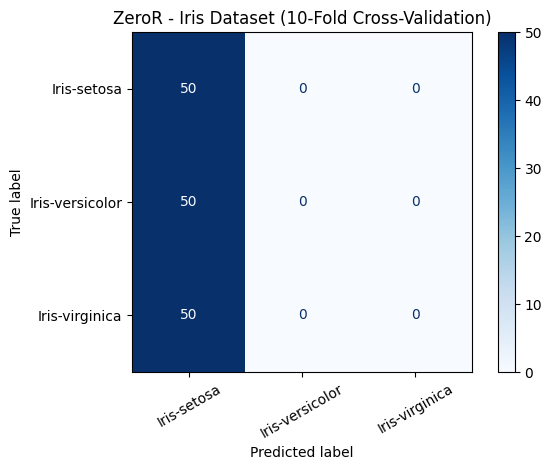

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y,
    predictions,
    labels=classes,
    display_labels=classes,
    cmap="Blues"
)

plt.title("ZeroR - Iris Dataset (10-Fold Cross-Validation)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()